# Reinforcement Learning: Agent Endless Runner ala Temple Run

| Nama | NRP |
|------|-----|
| Maria Putu Evelyne Corena Puryatma | 5054251011 |

**Link video presentasi:** https://youtu.be/jE80cz-OMmI

## Deskripsi Project

Project ini membuat agent yang bisa main game endless runner 3 lajur mirip Temple Run. Tujuannya bertahan selama mungkin tanpa menabrak rintangan. Algoritma yang dipakai **Q-learning** (tabular).

Aturan game (ada di `runner_env.py`):
1. Ada 3 lajur dan 8 baris. Pemain selalu di baris paling bawah.
2. Tiap 3 langkah muncul rintangan di 1–2 lajur (selalu ada lajur yang kosong), lalu rintangan maju 1 baris tiap langkah.
3. **Tembok** hanya bisa dihindari dengan pindah lajur. **Kayu** bisa dilompati atau dihindari.
4. Episode selesai kalau pemain nabrak atau sudah bertahan 500 langkah.

## Konsep RL di Project Ini


1. Agent : Pemain yang dikendalikan Q-learning 
2. Environment : Class `RunnerEnv` di `runner_env.py` 
3. State : `(lajur pemain, kode lajur 0, kode lajur 1, kode lajur 2)`. Kode: 0 = kosong, 1–3 = tembok jarak 1–3, 4–6 = kayu jarak 1–3. Total 3×7×7×7 = 1029 state 
4. Action : kiri, diam, kanan, lompat 
5. Reward : +1 tiap langkah selamat, +0.5 kalau selamat sambil lompat, −100 kalau nabrak 
6. Policy : ε-greedy saat training, greedy (pilih Q terbesar) saat evaluasi 
7. Value : Q(s, a) disimpan di Q-table ukuran 3×7×7×7×4 

Alasan desain reward:
1. −100 dibuat jauh lebih besar dari +1 supaya nabrak jadi hal yang paling dihindari agent.
2. Lompat dikasih biaya 0.5 supaya agent tidak lompat terus-menerus walaupun tidak perlu.

## 1. Import Library

Environment diambil dari `runner_env.py`, jadi file itu harus satu folder dengan notebook ini.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from runner_env import RunnerEnv, STATE_SHAPE, N_ACTIONS, ACTION_NAMES, VIEW, WALL, LOG

## 2. Training Q-learning

Rumus update Q-learning:

$$Q(s,a) \leftarrow Q(s,a) + \alpha \left[ r + \gamma \max_{a'} Q(s',a') - Q(s,a) \right]$$

Parameter yang dipakai:
1. `alpha = 0.1` (learning rate), `gamma = 0.9` (discount factor).
2. ε mulai dari 1.0 lalu dikali 0.995 tiap episode sampai minimal 0.01. Awalnya agent banyak eksplorasi (aksi acak), lama-lama lebih banyak eksploitasi (pilih Q terbesar).
3. Training 2000 episode, diulang dengan 3 seed (0, 1, 2) untuk melihat apakah hasilnya konsisten.

Catatan:
1. Kalau nabrak, target cukup `r` (−100) karena game sudah selesai dan tidak ada state berikutnya.
2. Kalau episode berhenti karena sudah 500 langkah, target tetap pakai `max Q(s')` karena agent sebenarnya belum kalah.
3. Q-table seed 0 disimpan ke `q_table.npy` untuk dipakai `watch_agent.py`.

In [2]:
def choose_action(Q, s, eps, rng):
    if rng.random() < eps:
        return int(rng.integers(N_ACTIONS))                 # eksplorasi
    q = Q[s]
    return int(rng.choice(np.flatnonzero(q == q.max())))    # eksploitasi

def train(episodes=2000, alpha=0.1, gamma=0.9, eps_start=1.0, eps_end=0.01, eps_decay=0.995, seed=0):
    rng = np.random.default_rng(seed)
    env = RunnerEnv(seed=seed)
    Q = np.zeros(STATE_SHAPE + (N_ACTIONS,))
    eps, scores = eps_start, []
    for _ in range(episodes):
        s, done = env.reset(), False
        while not done:
            a = choose_action(Q, s, eps, rng)
            s2, r, done = env.step(a)
            target = r if done and r < 0 else r + gamma * Q[s2].max()
            Q[s + (a,)] += alpha * (target - Q[s + (a,)])
            s = s2
        scores.append(env.t)                                # skor = langkah bertahan
        eps = max(eps_end, eps * eps_decay)
    return Q, np.array(scores)

SEEDS = [0, 1, 2]
runs = [train(seed=sd) for sd in SEEDS]
Q = runs[0][0]
np.save("q_table.npy", Q)                                   # dipakai oleh watch_agent.py

## 3. Learning Curve

Skor = jumlah langkah bertahan di tiap episode, dirata-rata tiap 50 episode supaya grafiknya lebih halus.

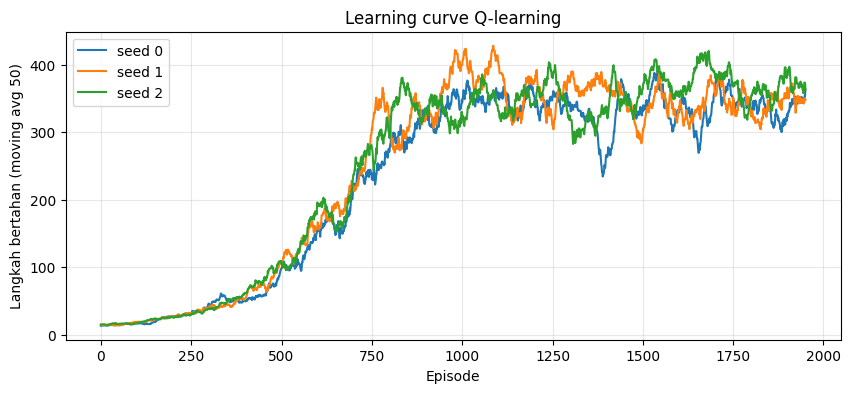

In [3]:
def smooth(x, k=50):
    return np.convolve(x, np.ones(k) / k, mode="valid")

plt.figure(figsize=(10, 4))
for sd, (_, sc) in zip(SEEDS, runs):
    plt.plot(smooth(sc), label=f"seed {sd}")
plt.xlabel("Episode"); plt.ylabel("Langkah bertahan (moving avg 50)")
plt.title("Learning curve Q-learning"); plt.legend(); plt.grid(alpha=.3)
plt.show()

### Analisis Learning Curve

1. Di awal agent cuma bertahan sekitar 15 langkah, sama saja seperti main acak, karena ε masih tinggi dan Q-table masih kosong.
2. Skor naik pesat di sekitar episode 500–800, lalu stabil di kisaran 350.
3. Skor stabil di 350, bukan 500, karena ε minimal masih 0.01. Dalam 500 langkah ada sekitar 5 aksi acak, dan satu aksi acak yang salah sudah cukup untuk bikin nabrak.
4. Ketiga seed polanya mirip, jadi hasil training tidak kebetulan.

## 4. Evaluasi Policy

Agent dites 100 episode dengan seed lain (999) tanpa eksplorasi (greedy). Pembandingnya agent random dan agent yang selalu diam. `finish` = persentase episode yang berhasil sampai 500 langkah.

In [4]:
def evaluate(policy, n=100, seed=999):
    rng = np.random.default_rng(seed)
    env = RunnerEnv(seed=seed)
    scores = []
    for _ in range(n):
        s, done = env.reset(), False
        while not done:
            s, r, done = env.step(policy(s, rng))
        scores.append(env.t)
    scores = np.array(scores)
    return scores.mean(), (scores >= env.max_steps).mean()

policies = {
    "Random": lambda s, rng: int(rng.integers(N_ACTIONS)),
    "Selalu diam": lambda s, rng: 1,
    "Q-learning": lambda s, rng: int(Q[s].argmax()),
}
for name, p in policies.items():
    m, f = evaluate(p)
    print(f"{name:<14} rata-rata langkah {m:6.1f} | finish {f:.0%}")

Random         rata-rata langkah   15.0 | finish 0%
Selalu diam    rata-rata langkah   12.6 | finish 0%


Q-learning     rata-rata langkah  500.0 | finish 100%


### Analisis Evaluasi

1. Q-learning rata-rata 500 langkah dengan finish 100%, sedangkan random cuma 15.0 langkah dan selalu diam 12.6 langkah (keduanya finish 0%).
2. Selalu diam lebih jelek dari random karena pasti nabrak begitu ada rintangan di lajur tengah, sedangkan random kadang kebetulan pindah lajur.
3. Seed evaluasi beda dengan training, jadi agent bukan menghafal urutan rintangan, tapi sudah tahu harus ngapain di tiap state.
4. Skor evaluasi (500) lebih tinggi dari learning curve (±350) karena saat evaluasi tidak ada aksi acak lagi.

## 5. Value Tiap Aksi

Melihat isi Q-table di beberapa state contoh (pemain di lajur tengah). Bar hijau = aksi yang dipilih policy.

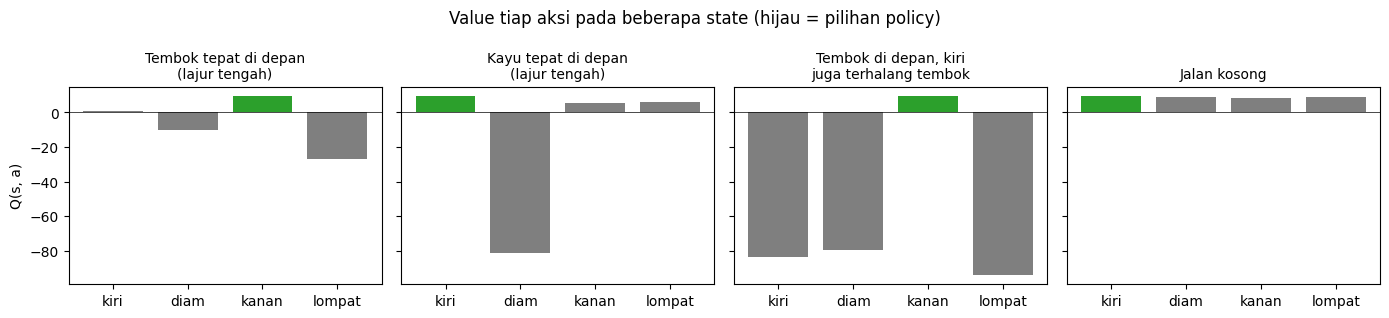

In [5]:
def code(kind, dist):
    return 1 + (kind - 1) * VIEW + (dist - 1)

examples = {
    "Tembok tepat di depan\n(lajur tengah)": (1, 0, code(WALL, 1), 0),
    "Kayu tepat di depan\n(lajur tengah)": (1, 0, code(LOG, 1), 0),
    "Tembok di depan, kiri\njuga terhalang tembok": (1, code(WALL, 1), code(WALL, 1), 0),
    "Jalan kosong": (1, 0, 0, 0),
}
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2), sharey=True)
for ax, (title, s) in zip(axes, examples.items()):
    q = Q[s]
    colors = ["tab:green" if i == q.argmax() else "tab:gray" for i in range(N_ACTIONS)]
    ax.bar(ACTION_NAMES, q, color=colors)
    ax.set_title(title, fontsize=10); ax.axhline(0, color="k", lw=.5)
axes[0].set_ylabel("Q(s, a)")
plt.suptitle("Value tiap aksi pada beberapa state (hijau = pilihan policy)")
plt.tight_layout(); plt.show()

### Analisis Value

1. **Tembok di depan:** kanan paling tinggi (±9), sedangkan lompat sekitar −27 karena lompat tidak bisa melewati tembok.
2. **Kayu di depan:** diam sekitar −80 karena pasti nabrak. Agent pilih pindah ke kiri daripada lompat, karena lompat ada biaya 0.5.
3. **Tembok di depan dan di kiri:** cuma kanan yang positif, aksi lain sekitar −80 sampai −95. Agent tahu satu-satunya jalan keluar adalah ke kanan.
4. **Jalan kosong:** semua aksi nilainya hampir sama (±9), jadi aksi apa pun aman. Nilainya mendekati 10 karena reward +1 terus-menerus dengan γ = 0.9 → 1 / (1 − 0.9) = 10.

## 6. Eksperimen: Pengaruh ε-decay

ε dikali `eps_decay` tiap episode. Dibandingkan 0.95 (ε turun cepat), 0.995 (default), dan 0.999 (ε turun lambat). Skor dirata-rata dari 3 seed.

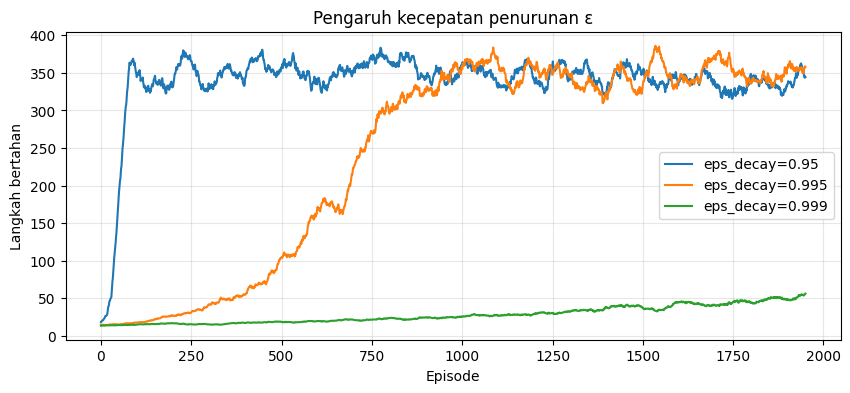

In [6]:
plt.figure(figsize=(10, 4))
for dec in [0.95, 0.995, 0.999]:
    sc = np.mean([train(eps_decay=dec, seed=sd)[1] for sd in SEEDS], axis=0)
    plt.plot(smooth(sc), label=f"eps_decay={dec}")
plt.xlabel("Episode"); plt.ylabel("Langkah bertahan")
plt.title("Pengaruh kecepatan penurunan ε"); plt.legend(); plt.grid(alpha=.3)
plt.show()

### Analisis ε-decay

1. **0.95:** ε sudah 0.01 di sekitar episode 90, skor langsung naik ke ±350 sebelum episode 100.
2. **0.995:** butuh sekitar 800 episode untuk sampai ±350.
3. **0.999:** skor masih di bawah 100 sampai episode 2000, karena ε baru turun ke 0.999²⁰⁰⁰ ≈ 0.14, jadi agent masih sering ambil aksi acak.
4. Environment ini simpel (state-nya cuma 1029), jadi eksplorasi sedikit sudah cukup. Di game yang lebih kompleks, ε yang turun terlalu cepat bisa bikin agent tidak sempat eksplorasi semua kemungkinan.

## Kesimpulan

1. Q-learning berhasil: dari ±15 langkah (setara random) jadi 500 langkah dengan finish 100% setelah 2000 episode training.
2. Agent belajar sendiri hanya dari reward: tembok dihindari dengan pindah lajur, kayu juga lebih sering dihindari dengan pindah lajur karena lompat ada biayanya.
3. Desain reward sangat menentukan perilaku agent. Contohnya biaya lompat 0.5 yang bikin agent jarang lompat.
4. ε-decay menentukan seberapa cepat agent belajar. Untuk environment ini, 0.95 paling cepat dan 0.999 terlalu lambat.

## Saran

1. Tambah tingkat kesulitan, misalnya rintangan makin cepat seiring waktu atau ada jenis rintangan baru (harus merunduk).
2. Kalau state-nya jadi besar (misalnya pakai gambar layar), Q-table tidak cukup lagi, jadi perlu diganti ke DQN.
3. Coba ubah biaya lompat dan γ untuk melihat pengaruhnya ke perilaku agent.

## Cara Menonton Agent

Setelah cell training dijalankan (`q_table.npy` sudah ada), jalankan di terminal:

```
python watch_agent.py agent    # agent hasil Q-learning
python watch_agent.py random   # agent acak (pembanding)
python watch_agent.py human    # main sendiri pakai keyboard
```

## Sumber

1. Sutton, R. S., & Barto, A. G. (2018). *Reinforcement Learning: An Introduction* (2nd ed.). MIT Press. (Q-learning dan ε-greedy)
2. Watkins, C. J. C. H., & Dayan, P. (1992). Q-learning. *Machine Learning*, 8, 279–292.
3. Ide game dari Temple Run (Imangi Studios). Yang diambil hanya konsep endless runner dengan tambahan 3 lajur. Environment dan tampilannya dibantu oleh AI menggunakan library pygame.
4. pygame (https://www.pygame.org) untuk tampilan game di `watch_agent.py`.